<a href="https://colab.research.google.com/github/mahmutsamiseyhan/yol-hasar-tespit/blob/main/notebooks/01_model_egitimi_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Yol Hasarı Tespiti: Model Eğitimi (Google Colab)

Bu notebook RDD2022 verisiyle bir YOLO11 modelini eğitir, modelin hiç görmediği test bölümünde ölçer,
hata analizini çıkarır ve sunum için gereken tüm grafikleri Google Drive'a kaydeder.

**Başlamadan önce:** `Çalışma zamanı → Çalışma zamanı türünü değiştir → T4 GPU`

| Adım | Süre (T4, tahmini) |
|---|---|
| Veri indirme + dönüştürme | ~10-15 dk |
| Hızlı deneme (`QUICK=True`) | ~5 dk |
| Tam eğitim | saatler sürebilir; ilk epoch süresine bakıp `EPOCHS`'u ayarlayın. Oturum koparsa aynı hücreyi tekrar çalıştırın, Drive'daki son noktadan devam eder. |

Veri: Arya ve ark. (2022), *RDD2022: A multi-national image dataset for automatic Road Damage Detection*, figshare, CC BY 4.0.

## 1. Ortam

In [6]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
from google.colab import drive
drive.mount('/content/drive')

DRIVE_DIR = '/content/drive/MyDrive/yol-hasar-tespit'
import os; os.makedirs(DRIVE_DIR, exist_ok=True)

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# Kendi GitHub deponuzun adresini yazın
REPO_URL = 'https://github.com/mahmutsamiseyhan/yol-hasar-tespit.git'

!git clone -q {REPO_URL} /content/yol-hasar-tespit || (cd /content/yol-hasar-tespit && git pull -q)
%cd /content/yol-hasar-tespit
!pip install -q ultralytics remotezip

fatal: destination path '/content/yol-hasar-tespit' already exists and is not an empty directory.
/content/yol-hasar-tespit


## 2. Veri: RDD2022 indir ve YOLO formatına çevir

Varsayılan ülkeler: Çekya, Hindistan, Japonya, ABD, Çin (motosiklet). Norveç (10.6 GB, çok yüksek çözünürlük)
ve Çin drone (kuşbakışı, araç kamerası senaryosuna uymuyor) atlanır. Yalnızca seçilen ülkeler indirilir (~2.6 GB).

RDD2022'nin resmi test bölümü **etiketsiz** olduğu için etiketli veri ülke bazında 80/10/10 olarak
train/val/test'e ayrılır. Test metrikleri modelin hiç görmediği görüntülerden ölçülür.

In [8]:
!python scripts/download_rdd2022.py --out /content/rdd_raw
!python scripts/prepare_rdd2022.py --src /content/rdd_raw --out /content/rdd_yolo
DATA_YAML = '/content/rdd_yolo/data.yaml'

Czech: zaten var, atlanıyor
India: zaten var, atlanıyor
Japan: 1073 MB indiriliyor...
Japan: açıldı -> /content/rdd_raw/Japan
United_States: 444 MB indiriliyor...
United_States: açıldı -> /content/rdd_raw/United_States
China_MotorBike: 192 MB indiriliyor...
China_MotorBike: açıldı -> /content/rdd_raw/China_MotorBike
Tamam.
27823 XML, 34818 görüntü bulundu
18934 etiketli + 3341 hasarsız görüntü kullanılacak
{
  "train": {
    "goruntu": 17818,
    "sinif_ornekleri": {
      "D00": 12800,
      "D10": 7051,
      "D20": 7888,
      "D40": 4833
    },
    "ulkeler": {
      "China_MotorBike": 1561,
      "Czech": 1418,
      "India": 3895,
      "Japan": 7100,
      "United_States": 3844
    }
  },
  "val": {
    "goruntu": 2225,
    "sinif_ornekleri": {
      "D00": 1579,
      "D10": 942,
      "D20": 991,
      "D40": 595
    },
    "ulkeler": {
      "China_MotorBike": 195,
      "Czech": 177,
      "India": 486,
      "Japan": 887,
      "United_States": 480
    }
  },
  "test": {
  

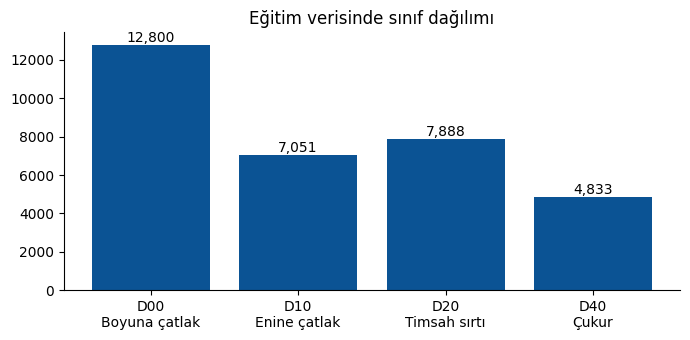

{'train': 17818, 'val': 2225, 'test': 2232}


In [9]:
# Sunum için: sınıf dağılımı grafiği
import json, matplotlib.pyplot as plt
stats = json.load(open('/content/rdd_yolo/stats.json'))
names = {'D00': 'Boyuna çatlak', 'D10': 'Enine çatlak', 'D20': 'Timsah sırtı', 'D40': 'Çukur'}
train = stats['train']['sinif_ornekleri']
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar([f"{k}\n{names[k]}" for k in train], train.values(), color='#0b5394')
for i, v in enumerate(train.values()):
    ax.text(i, v, f'{v:,}', ha='center', va='bottom')
ax.set_title('Eğitim verisinde sınıf dağılımı'); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(f'{DRIVE_DIR}/sinif_dagilimi.png', dpi=150); plt.show()
print({s: v['goruntu'] for s, v in stats.items()})

## 3. Eğitim

- `yolo11s`: doğruluk/hız dengesi iyi, araç içi cihazlarda ve CPU sunucuda çalışabilecek boyutta.
- Önce `QUICK=True` ile 5 dakikalık bir deneme yapıp hattın çalıştığını görün, sonra `False` yapıp tam eğitimi başlatın.
- Çıktılar doğrudan Drive'a yazılır. Oturum koparsa bu hücreyi tekrar çalıştırmanız yeterli: son kayıttan devam eder.

In [10]:
from pathlib import Path
from ultralytics import YOLO
import torch
assert torch.cuda.is_available(), (
    'GPU YOK! Eğitim CPU\'da günler sürer. Çalışma zamanı → Çalışma zamanı türünü değiştir → '
    'T4 veya L4 GPU seçin, sonra hücreleri baştan çalıştırın.')
print('GPU:', torch.cuda.get_device_name(0))


QUICK = False          # İlk denemede True, sonra False
MODEL = 'yolo11s.pt'
EPOCHS = 3 if QUICK else 80
RUN_NAME = 'deneme' if QUICK else 'rdd2022_yolo11s'
PROJECT = f'{DRIVE_DIR}/runs'

last = Path(PROJECT) / RUN_NAME / 'weights' / 'last.pt'
if last.exists() and not QUICK:
    print('Yarım kalan eğitim bulundu, devam ediliyor:', last)
    model = YOLO(str(last))
    model.train(resume=True)
else:
    model = YOLO(MODEL)
    model.train(
        data=DATA_YAML, epochs=EPOCHS, imgsz=640, batch=16, patience=20,
        fraction=0.1 if QUICK else 1.0,
        project=PROJECT, name=RUN_NAME, exist_ok=True,
        cos_lr=True, close_mosaic=10, seed=42, plots=True,
    )
# Ultralytics'in gerçekte kullandığı klasör (sürüme göre yol yapısı değişebiliyor)
RUN_DIR = Path(model.trainer.save_dir)
BEST = RUN_DIR / 'weights' / 'best.pt'
print('En iyi ağırlıklar:', BEST)

GPU: NVIDIA L4
Yarım kalan eğitim bulundu, devam ediliyor: /content/drive/MyDrive/yol-hasar-tespit/runs/rdd2022_yolo11s/weights/last.pt
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/rdd_yolo/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.00125, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode

results.png


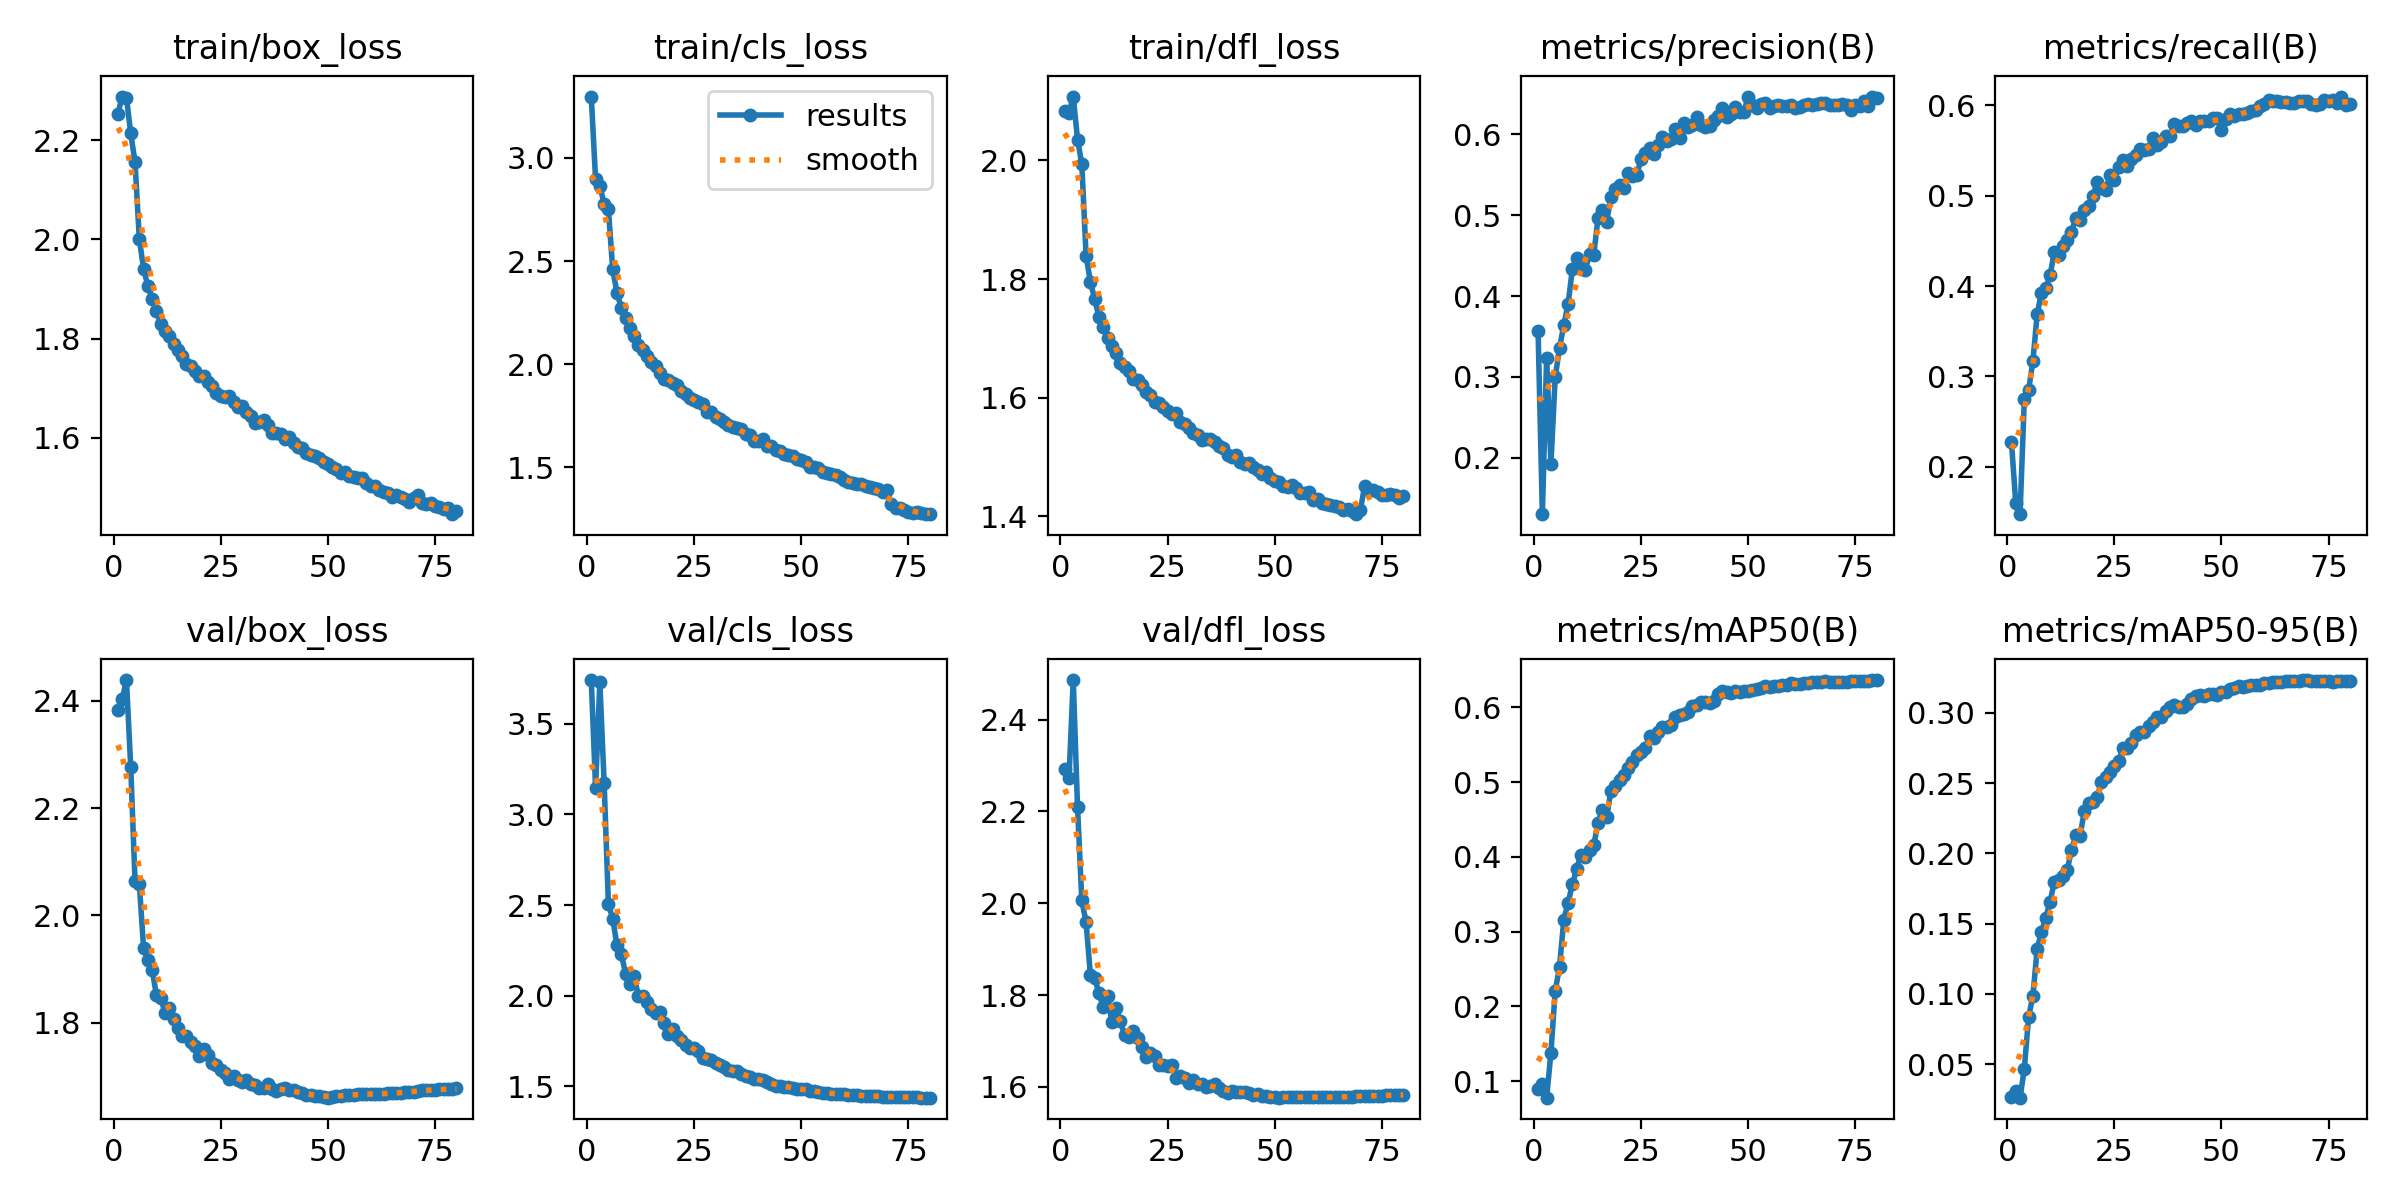

confusion_matrix_normalized.png


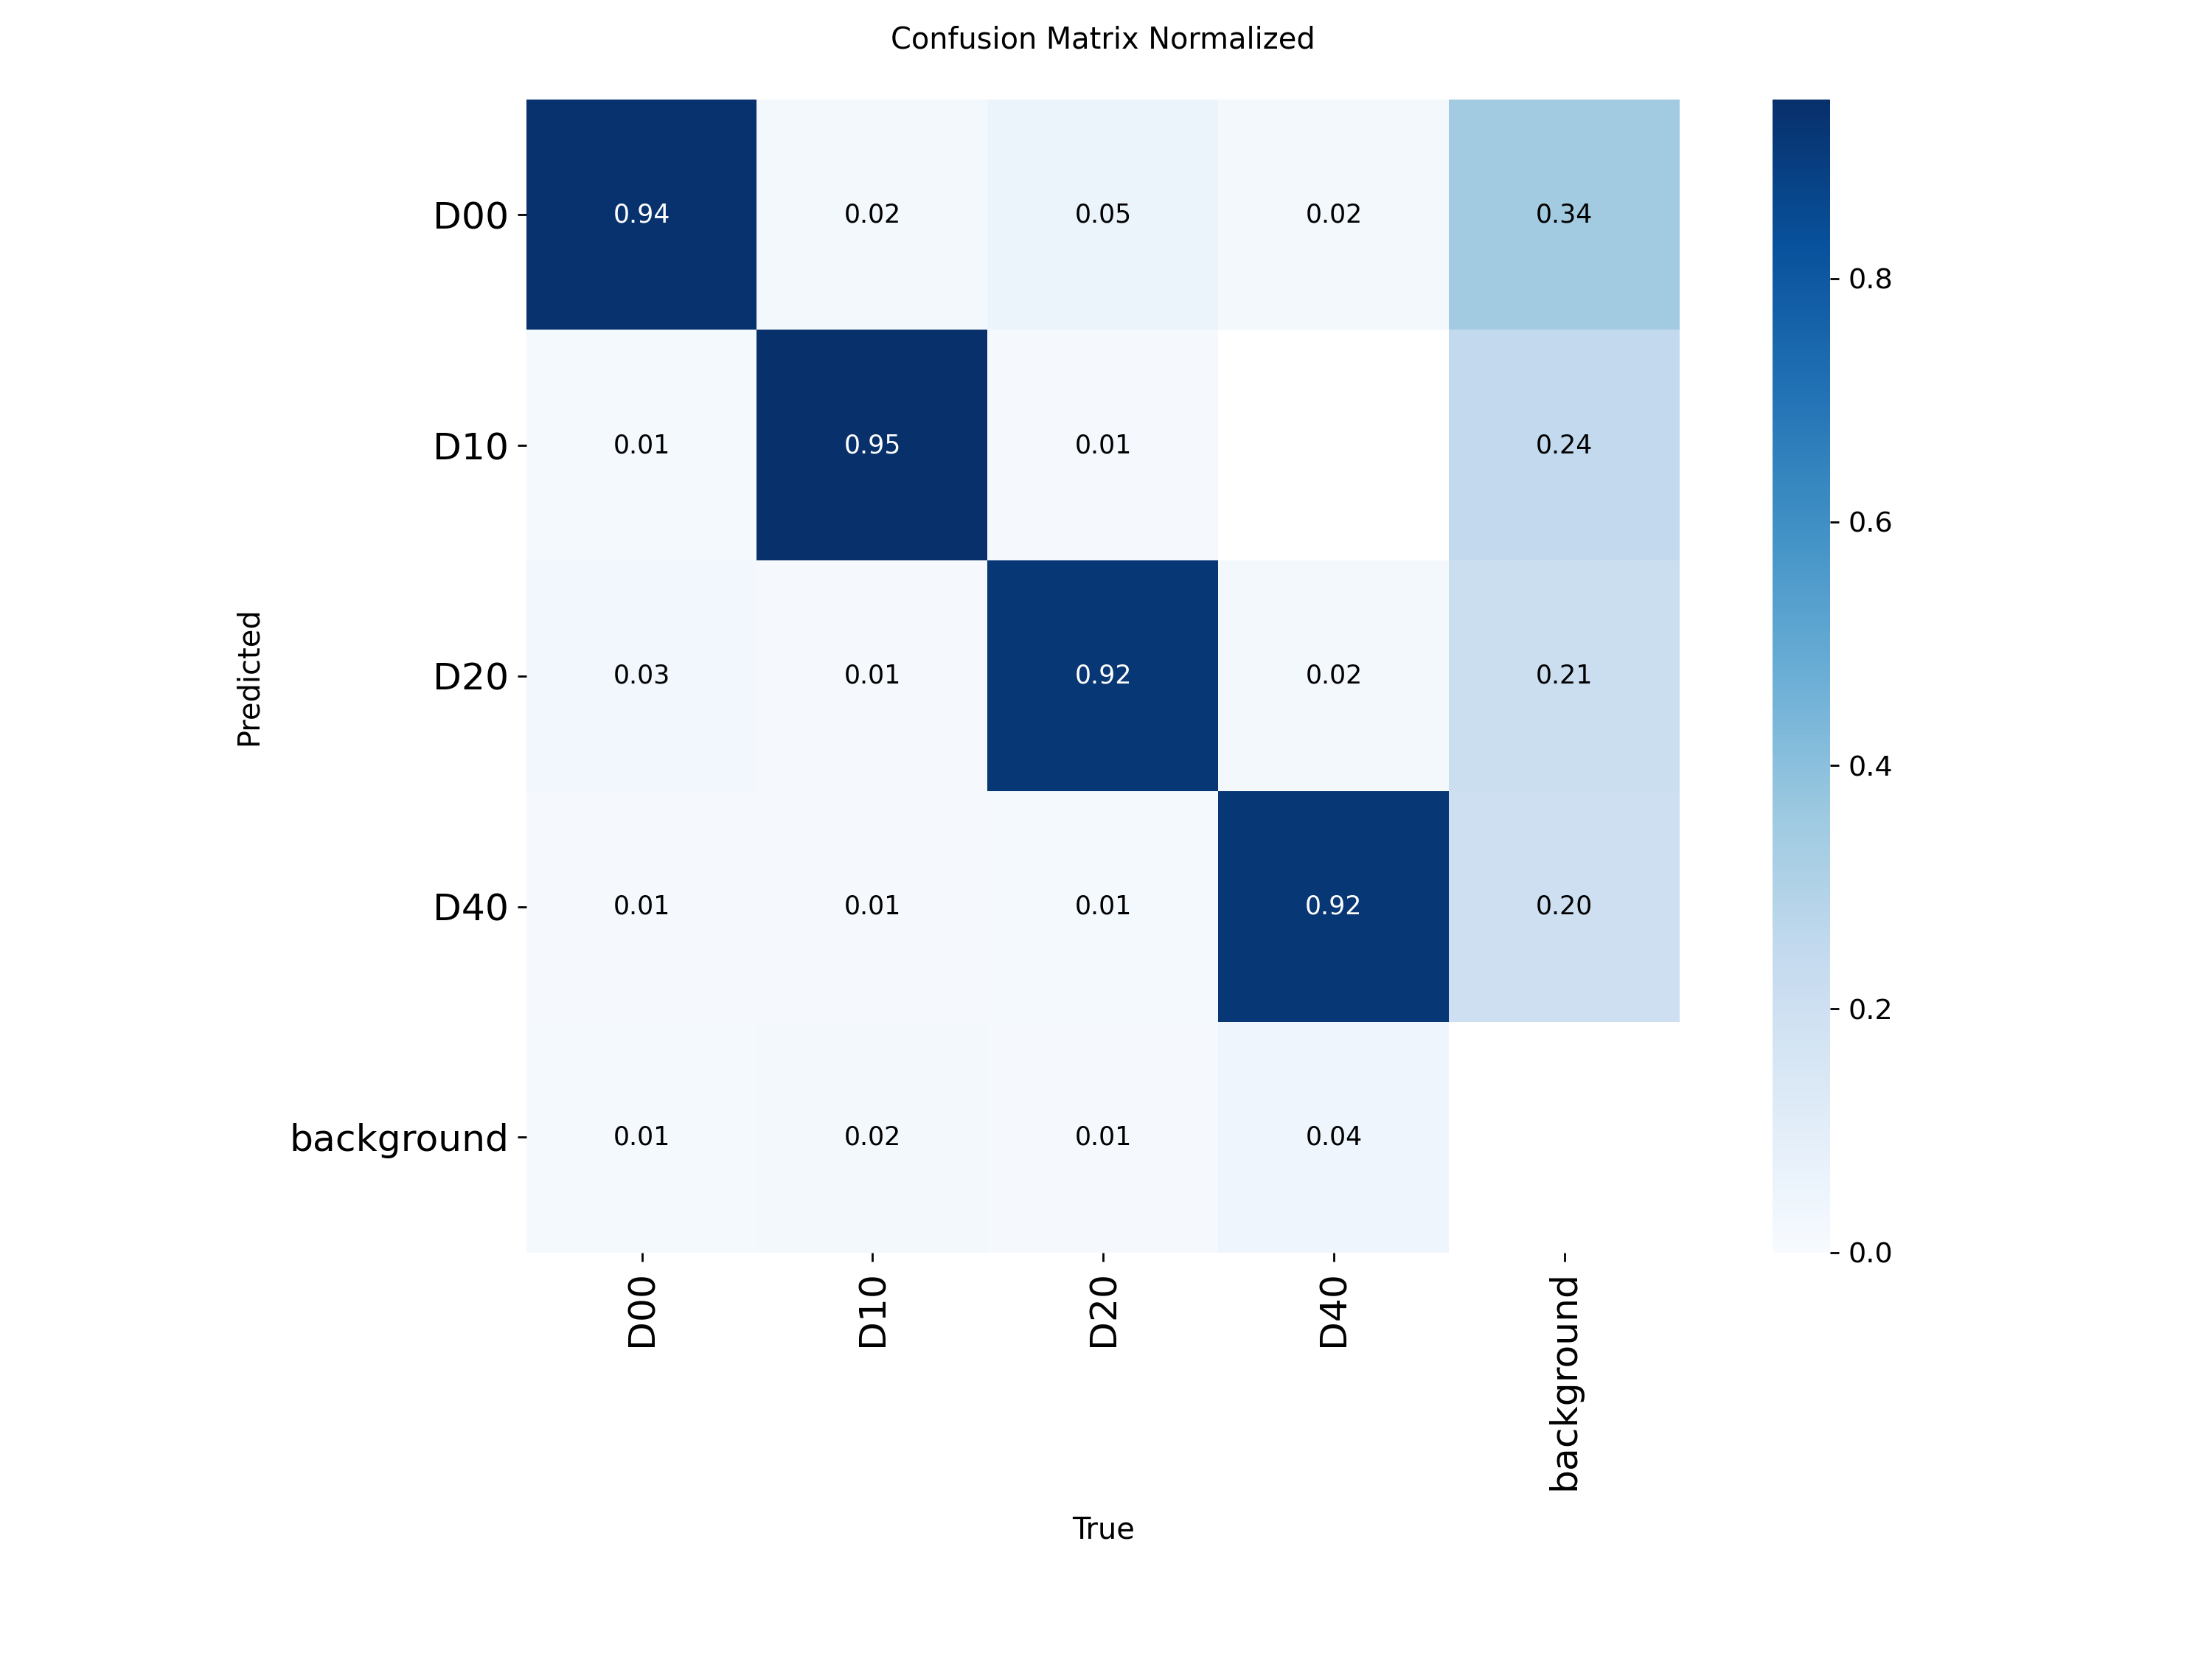

BoxPR_curve.png


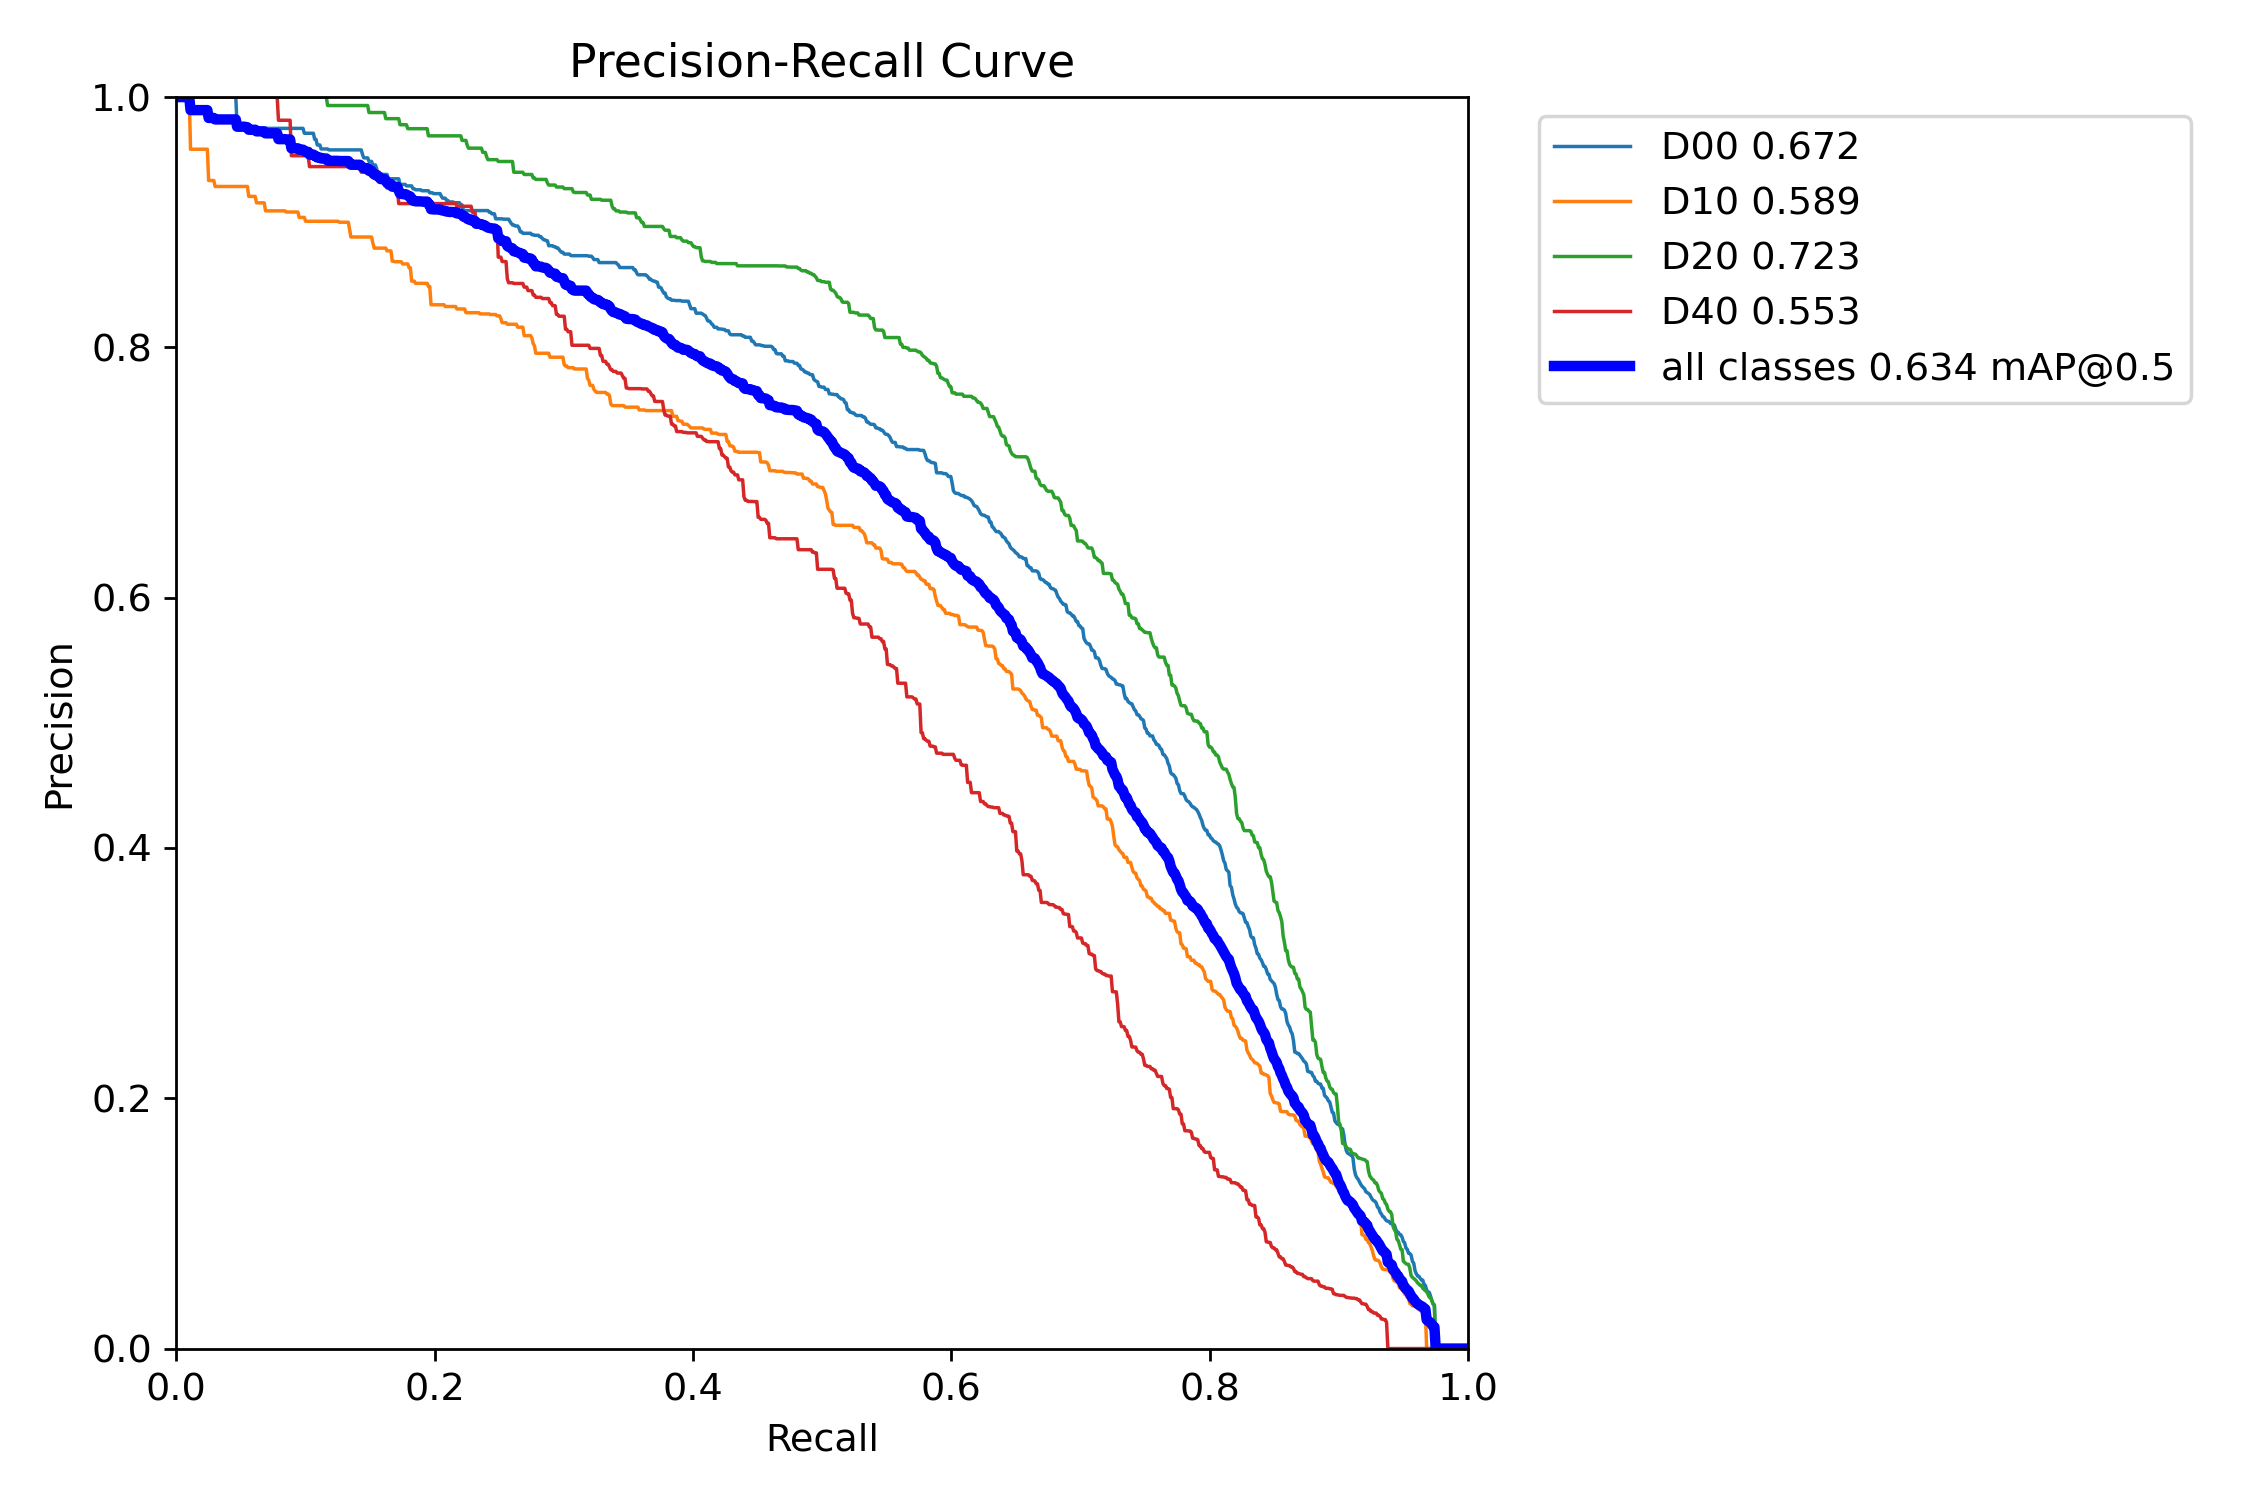

In [11]:
# Eğitim grafikleri (sunuma doğrudan konabilir)
from IPython.display import Image, display
for name in ['results.png', 'confusion_matrix_normalized.png', 'BoxPR_curve.png', 'PR_curve.png']:
    p = RUN_DIR / name
    if p.exists():
        print(name); display(Image(filename=str(p), width=900))

## 4. Test bölümünde değerlendirme

Burada ölçülen değerler sunumda söyleyeceğiniz rakamlardır. Kendi ölçtüğünüz rakamı söyleyin, yuvarlamayın.
Karşılaştırma için: RDD2022 üzerinde YOLOv7 ile 4 sınıfta mAP@0.5 = %63.9 raporlayan açık kaynak bir çalışma var
(github.com/oracl4/RoadDamageDetection). Farklı veri bölümleri kullanıldığı için birebir karşılaştırma değildir.

In [12]:
import pandas as pd
best_model = YOLO(str(BEST))
m = best_model.val(data=DATA_YAML, split='test', imgsz=640, batch=16, plots=True,
                   project=PROJECT, name=f'{RUN_NAME}_test', exist_ok=True)

rows = []
for i, cls_id in enumerate(m.box.ap_class_index):  # yalnızca test setinde bulunan sınıflar
    c = m.names[int(cls_id)]
    p, r, ap50, ap = m.box.class_result(i)
    rows.append({'sinif': c, 'ad': names.get(c, c), 'precision': p, 'recall': r, 'AP50': ap50, 'AP50-95': ap})
rows.append({'sinif': 'TÜMÜ', 'ad': '', 'precision': m.box.mp, 'recall': m.box.mr, 'AP50': m.box.map50, 'AP50-95': m.box.map})
test_table = pd.DataFrame(rows).round(3)
display(test_table)

metrics = {
    'test': test_table.to_dict(orient='records'),
    'hiz_ms': m.speed,   # görüntü başına ön-işleme / çıkarım / son-işleme (ms, T4)
    'goruntu_sayisi': stats['test']['goruntu'],
}
json.dump(metrics, open(f'{DRIVE_DIR}/test_metrikleri.json', 'w'), indent=2, ensure_ascii=False)
print('Hız (ms/görüntü):', m.speed)

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1562.0±600.1 MB/s, size: 59.8 KB)
val: Scanning /content/rdd_yolo/labels/test... 2232 images, 322 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2232/2232 1.5Kit/s 1.5s
val: New cache created: /content/rdd_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 140/140 7.2it/s 19.4s
                   all       2232       4030      0.622      0.578      0.621      0.316
                   D00       1032       1641      0.635      0.651      0.673      0.384
                   D10        565        844      0.602      0.584      0.617      0.294
                   D20        778        976      0.673      0.627      0.697      0.383
                   D40        310        569      0.578       0.45     

,sinif,ad,precision,recall,AP50,AP50-95
0,D00,Boyuna çatlak,0.635,0.651,0.673,0.384
1,D10,Enine çatlak,0.602,0.584,0.617,0.294
2,D20,Timsah sırtı,0.673,0.627,0.697,0.383
3,D40,Çukur,0.578,0.450,0.498,0.201
4,TÜMÜ,,0.622,0.578,0.621,0.316


Hız (ms/görüntü): {'preprocess': 0.7314714722289414, 'inference': 4.482722985660473, 'loss': 0.0005780344911411093, 'postprocess': 0.9240889162168885}


## 5. Hata analizi: model nerede yanılıyor?

Test görüntülerinde tahminler etiketlerle karşılaştırılır (IoU ≥ 0.5, aynı sınıf).
En yüksek güvenli **yanlış pozitifler** (model hasar dedi, etiket yok) ve **kaçırılanlar** gösterilir.
Tipik nedenler: rögar kapakları, yama yapılmış asfalt, gölgeler, ıslak zemin, yol çizgileri.
Bu slayt jüriye "sistemin sınırlarını biliyorum" mesajını verir.

Yanlış pozitif: 811, kaçırılan: 2017


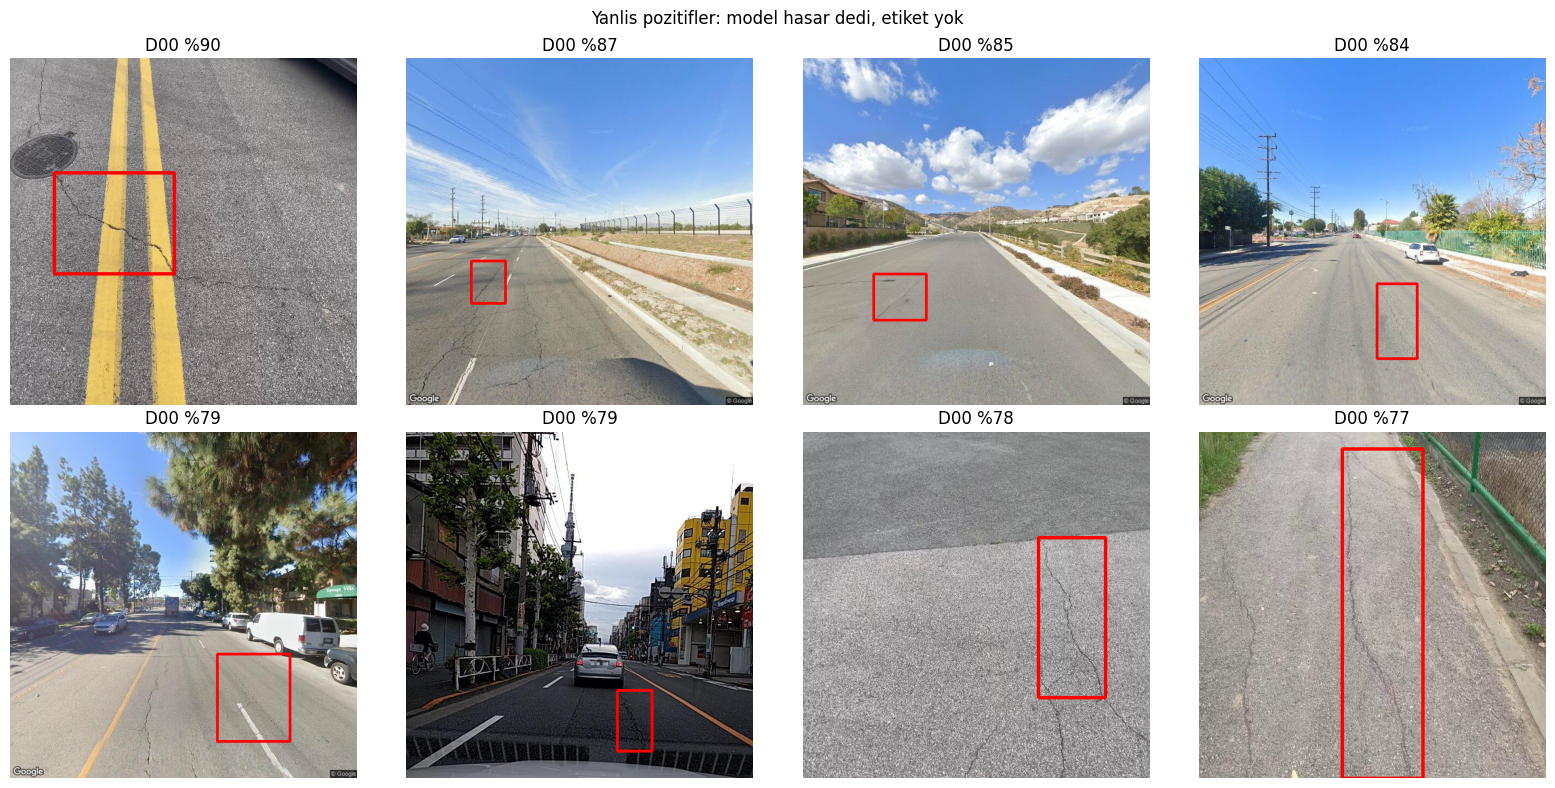

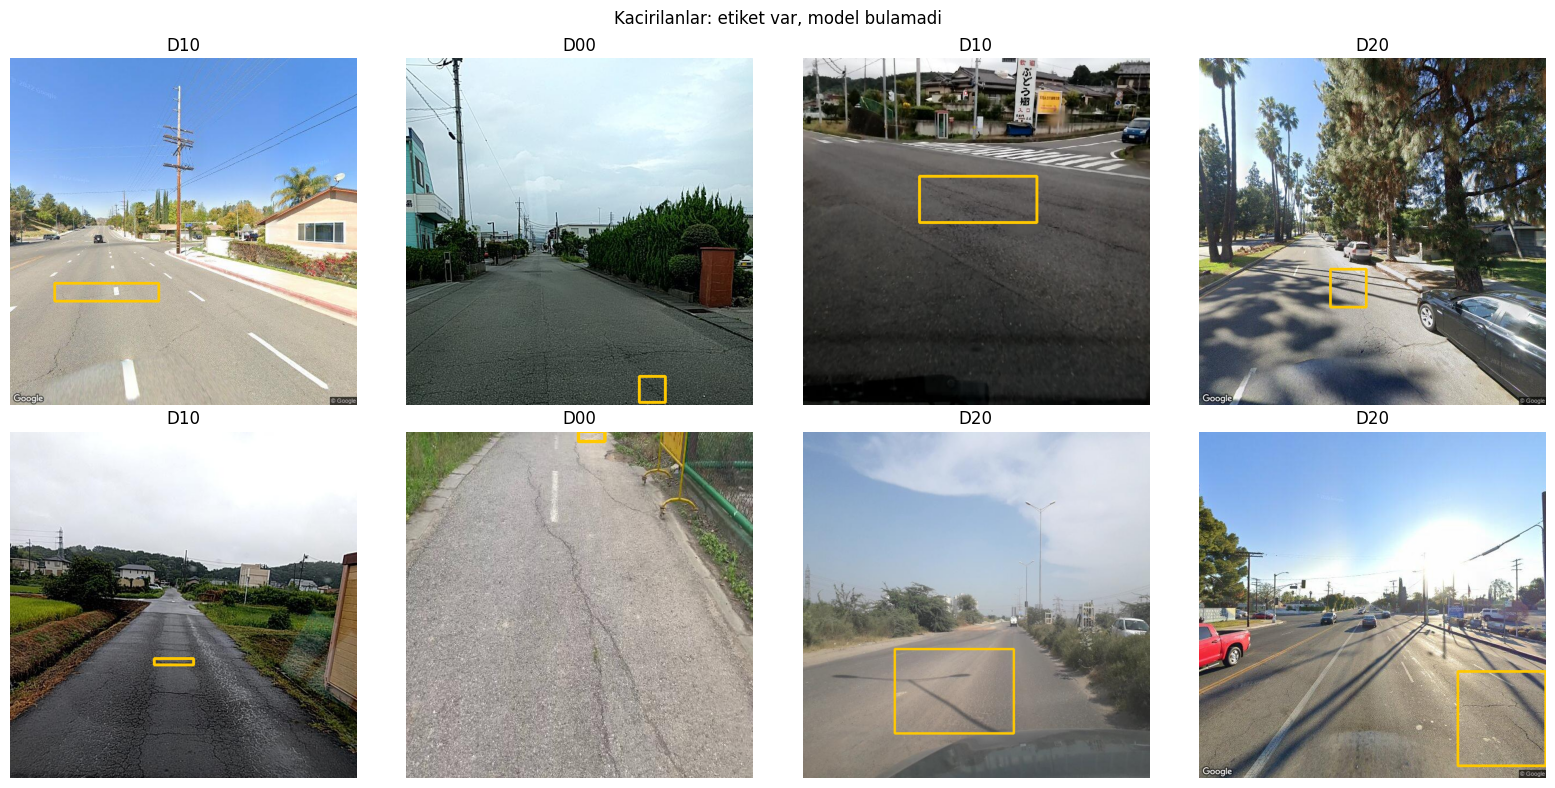

In [15]:
import numpy as np, cv2, random

def iou(a, b):
    x1, y1 = max(a[0], b[0]), max(a[1], b[1]); x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, x2 - x1) * max(0, y2 - y1)
    return inter / ((a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter + 1e-9)

def load_gt(img_path, w, h):
    lbl = Path(str(img_path).replace('/images/', '/labels/')).with_suffix('.txt')
    out = []
    for line in lbl.read_text().split('\n') if lbl.exists() else []:
        if line.strip():
            c, x, y, bw, bh = map(float, line.split())
            out.append((int(c), [(x-bw/2)*w, (y-bh/2)*h, (x+bw/2)*w, (y+bh/2)*h]))
    return out

test_imgs = sorted(Path('/content/rdd_yolo/images/test').glob('*.jpg'))
fps, fns = [], []
for res in best_model.predict('/content/rdd_yolo/images/test', conf=0.35, stream=True, verbose=False):
    h, w = res.orig_shape
    gt = load_gt(res.path, w, h); matched = set()
    for box, c, conf in zip(res.boxes.xyxy.tolist(), res.boxes.cls.tolist(), res.boxes.conf.tolist()):
        hit = next((j for j, (gc, gb) in enumerate(gt) if j not in matched and gc == int(c) and iou(box, gb) >= 0.5), None)
        if hit is None: fps.append((conf, res.path, box, m.names[int(c)]))
        else: matched.add(hit)
    for j, (gc, gb) in enumerate(gt):
        if j not in matched: fns.append((res.path, gb, m.names[gc]))

print(f'Yanlış pozitif: {len(fps)}, kaçırılan: {len(fns)}')

def show(items, title, color, n=8):
    fig, axes = plt.subplots(2, 4, figsize=(16, 8)); fig.suptitle(title)
    for ax, it in zip(axes.flat, items[:n]):
        path, box, label = (it[1], it[2], it[3]) if len(it) == 4 else it
        img = cv2.cvtColor(cv2.imread(path), cv2.COLOR_BGR2RGB)
        x1, y1, x2, y2 = map(int, box); cv2.rectangle(img, (x1, y1), (x2, y2), color, 4)
        ax.imshow(img); ax.set_title(f'{label}' + (f' %{it[0]*100:.0f}' if len(it) == 4 else '')); ax.axis('off')
    plt.tight_layout(); plt.savefig(f'{DRIVE_DIR}/{title.split(":")[0].replace(" ", "_").lower()}.png', dpi=110); plt.show()

show(sorted(fps, reverse=True), 'Yanlis pozitifler: model hasar dedi, etiket yok', (255, 0, 0))
random.seed(0); show(random.sample(fns, min(8, len(fns))), 'Kacirilanlar: etiket var, model bulamadi', (255, 200, 0))

## 6. Bursa test seti (alan farkı / domain gap ölçümü)

RDD2022'de Türkiye verisi yok. Modelin Bursa yollarındaki gerçek performansı ayrıca ölçülmelidir.

1. `scripts/fetch_mapillary_bursa.py` ile Mapillary'den Bursa görüntüleri indirin ve/veya kendiniz fotoğraf çekin.
2. Aşağıdaki **model destekli ön-etiketleme** hücresiyle modelin tahminlerini YOLO etiketi olarak üretin.
3. Görüntü + etiketleri CVAT veya Roboflow'a yükleyip düzeltin (sıfırdan çizmekten çok daha hızlı).
4. Düzeltilmiş seti `DRIVE_DIR/bursa_test/` altına `images/` + `labels/` olarak koyun ve değerlendirme hücresini çalıştırın.

In [16]:
# Ön-etiketleme: Bursa görüntülerini Drive'da DRIVE_DIR/bursa_raw/ klasörüne koyun
BURSA_RAW = Path(DRIVE_DIR) / 'bursa_raw'
if BURSA_RAW.exists():
    best_model.predict(str(BURSA_RAW), conf=0.25, save_txt=True, save=True,
                       project=DRIVE_DIR, name='bursa_on_etiket', exist_ok=True, verbose=False)
    print('Ön-etiketler:', f'{DRIVE_DIR}/bursa_on_etiket/labels  (CVAT/Roboflow\'a YOLO formatında yükleyin)')
else:
    print('Bursa ham görüntüleri bulunamadı:', BURSA_RAW)

Bursa ham görüntüleri bulunamadı: /content/drive/MyDrive/yol-hasar-tespit/bursa_raw


In [17]:
# Değerlendirme: RDD test seti vs Bursa test seti
BURSA = Path(DRIVE_DIR) / 'bursa_test'
if (BURSA / 'images').exists():
    (BURSA / 'data.yaml').write_text(
        f"path: {BURSA}\ntrain: images\nval: images\ntest: images\nnames:\n  0: D00\n  1: D10\n  2: D20\n  3: D40\n")
    mb = best_model.val(data=str(BURSA / 'data.yaml'), split='test', imgsz=640, plots=True,
                        project=PROJECT, name=f'{RUN_NAME}_bursa', exist_ok=True)
    compare = pd.DataFrame({
        'RDD2022 test': [m.box.mp, m.box.mr, m.box.map50, m.box.map],
        'Bursa test': [mb.box.mp, mb.box.mr, mb.box.map50, mb.box.map],
    }, index=['precision', 'recall', 'mAP50', 'mAP50-95']).round(3)
    display(compare)
    metrics['bursa'] = compare.to_dict()
    json.dump(metrics, open(f'{DRIVE_DIR}/test_metrikleri.json', 'w'), indent=2, ensure_ascii=False)
else:
    print('Bursa test seti henüz yok:', BURSA)

Bursa test seti henüz yok: /content/drive/MyDrive/yol-hasar-tespit/bursa_test


## 7. Dışa aktarma

`best.pt` dosyasını Drive'dan indirip projede `models/best.pt` konumuna koyun.
ONNX çıktısı, PyTorch kurulu olmayan sunucularda veya araç içi cihazlarda çalıştırmak içindir.

In [18]:
import shutil
shutil.copy(BEST, f'{DRIVE_DIR}/best.pt')
onnx_path = best_model.export(format='onnx', imgsz=640, dynamic=False, simplify=True)
shutil.copy(onnx_path, f'{DRIVE_DIR}/best.onnx')
print('Drive\'a kaydedildi:', f'{DRIVE_DIR}/best.pt', f'{DRIVE_DIR}/best.onnx')

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CPU (Intel Xeon CPU @ 2.20GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,414,348 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/yol-hasar-tespit/runs/rdd2022_yolo11s/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 8, 8400) (18.3 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 476ms
Prepared 4 packages in 623ms
Installed 4 packages in 28ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.31.0
 + onnxslim==0.1.98

requirements: AutoUpdate success ✅ 1.4s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1

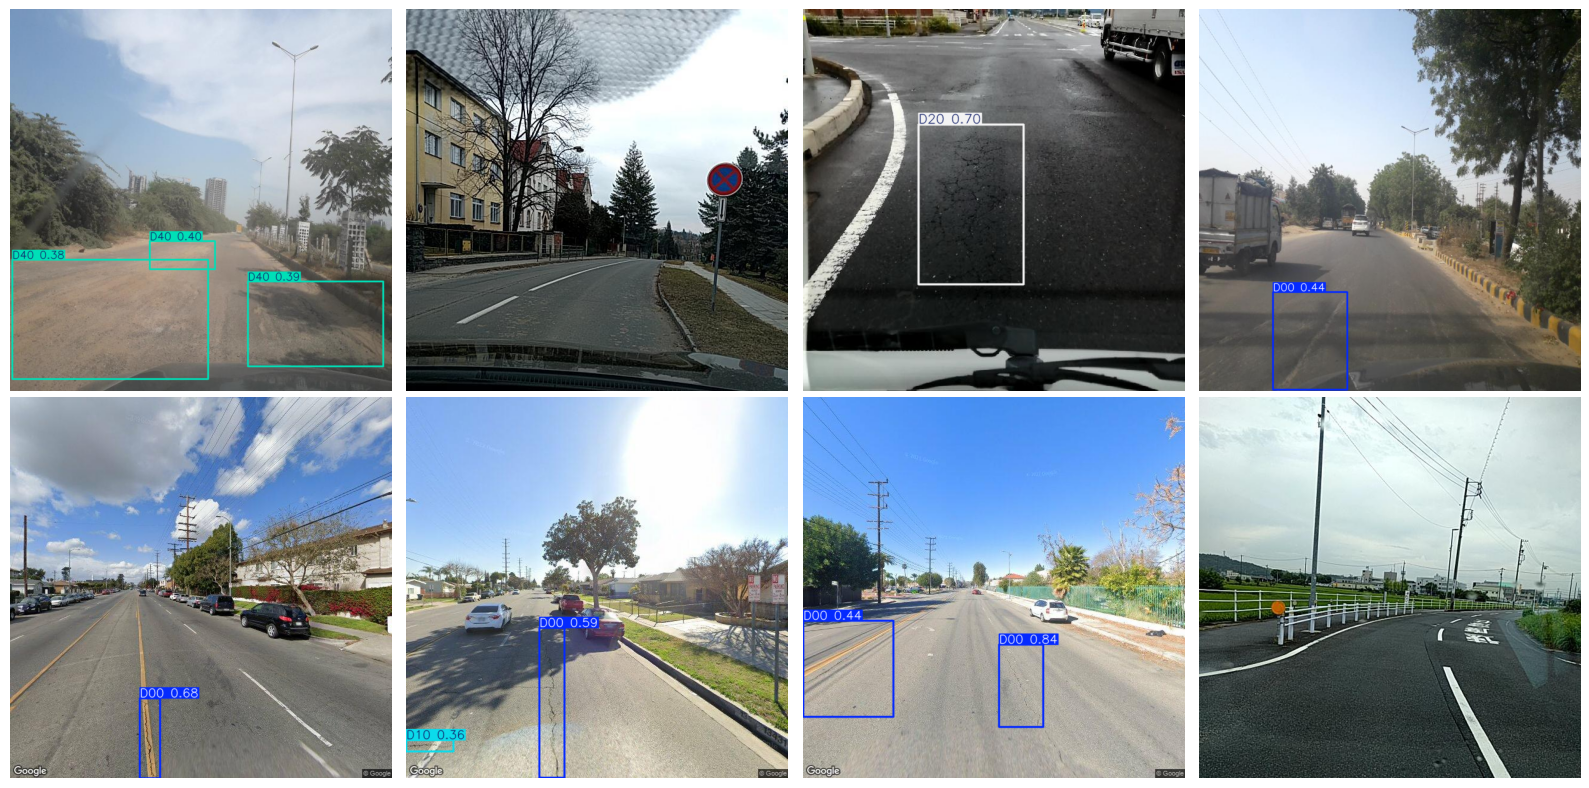

In [19]:
# Örnek tahminler (sunum için)
sample = random.Random(1).sample(test_imgs, 8)
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, res in zip(axes.flat, best_model.predict([str(p) for p in sample], conf=0.35, verbose=False)):
    ax.imshow(res.plot()[:, :, ::-1]); ax.axis('off')
plt.tight_layout(); plt.savefig(f'{DRIVE_DIR}/ornek_tahminler.png', dpi=110); plt.show()